*Importing Necessary Libraries*

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score

warnings.filterwarnings('ignore') # for ignoring warnings to keep the notebook clean (relevant issues are handled in later sections)

*Loading Dataset*

In [2]:
import pandas as pd

# Load the XLS file
file_path = 'lcrimedf.xlsx'  # Replace with your actual file path
df = pd.read_excel(file_path)
df.head()

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed,Locality,Population,Crime Score
0,1,2020-01-02 00:00:00,2020-01-01 00:00:00,2020-01-01 01:11:00,Ahmedabad,576,IDENTITY THEFT,16,M,Blunt Object,Violent Crime,13,No,NaT,Vastrapur,7692000,61
1,2,2020-01-01 19:00:00,2020-01-01 01:00:00,2020-01-01 06:26:00,Chennai,128,HOMICIDE,37,M,Poison,Other Crime,9,No,NaT,Tambaram,"7,22,982",99
2,3,2020-01-02 05:00:00,2020-01-01 02:00:00,2020-01-01 14:30:00,Ludhiana,271,KIDNAPPING,48,F,Blunt Object,Other Crime,15,No,NaT,Pakhowal Road,93300,89
3,4,2020-01-01 05:00:00,2020-01-01 03:00:00,2020-01-01 14:46:00,Pune,170,BURGLARY,49,F,Firearm,Other Crime,1,Yes,2020-04-29 05:00:00,Baner,23701,56
4,5,2020-01-01 21:00:00,2020-01-01 04:00:00,2020-01-01 16:51:00,Pune,421,VANDALISM,30,F,Other,Other Crime,18,Yes,2020-01-08 21:00:00,Hadapsar,6471,39


*Data Preprocessing*

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40160 entries, 0 to 40159
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Report Number       40160 non-null  int64         
 1   Date Reported       40160 non-null  datetime64[ns]
 2   Date of Occurrence  40160 non-null  object        
 3   Time of Occurrence  40160 non-null  datetime64[ns]
 4   City                40160 non-null  object        
 5   Crime Code          40160 non-null  int64         
 6   Crime Description   40160 non-null  object        
 7   Victim Age          40160 non-null  int64         
 8   Victim Gender       40160 non-null  object        
 9   Weapon Used         34370 non-null  object        
 10  Crime Domain        40160 non-null  object        
 11  Police Deployed     40160 non-null  int64         
 12  Case Closed         40160 non-null  object        
 13  Date Case Closed    20062 non-null  datetime64

In [4]:
df.describe()

,Report Number,Date Reported,Time of Occurrence,Crime Code,Victim Age,Police Deployed,Date Case Closed,Crime Score
count,40160.000000,40160,40160,40160.000000,40160.00000,40160.000000,20062,40160.000000
mean,20080.500000,2022-04-18 03:29:56.952191232,2022-04-17 03:26:55.228087808,349.360259,44.49126,10.006250,2022-07-15 10:08:33.388495616,63.962326
min,1.000000,2020-01-01 05:00:00,2020-01-01 01:11:00,100.000000,10.00000,1.000000,2020-01-08 21:00:00,20.000000
25%,10040.750000,2021-02-24 02:00:00,2021-02-22 20:22:15,225.000000,27.00000,5.000000,2021-05-14 21:15:00,51.000000
50%,20080.500000,2022-04-18 05:00:00,2022-04-17 01:16:00,349.000000,44.00000,10.000000,2022-07-15 21:30:00,61.000000
75%,30120.250000,2023-06-10 10:00:00,2023-06-09 10:10:15,474.000000,62.00000,15.000000,2023-09-08 19:45:00,80.000000
max,40160.000000,2024-08-02 18:00:00,2024-07-31 21:42:00,599.000000,79.00000,19.000000,2026-07-21 16:00:00,99.000000
std,11593.337742,NaN,NaN,144.169205,20.22555,5.467951,NaN,19.271014


In [5]:
df.shape

(40160, 17)

In [6]:
df.columns

Index(['Report Number', 'Date Reported', 'Date of Occurrence',
       'Time of Occurrence', 'City', 'Crime Code', 'Crime Description',
       'Victim Age', 'Victim Gender', 'Weapon Used', 'Crime Domain',
       'Police Deployed', 'Case Closed', 'Date Case Closed', 'Locality',
       'Population', 'Crime Score'],
      dtype='object')

In [7]:
df.nunique()

Report Number         40160
Date Reported         25546
Date of Occurrence    40160
Time of Occurrence    39886
City                     29
Crime Code              500
Crime Description        21
Victim Age               70
Victim Gender             3
Weapon Used               6
Crime Domain              4
Police Deployed          19
Case Closed               2
Date Case Closed      16011
Locality                142
Population              144
Crime Score              79
dtype: int64

*Checking for Duplicated Values*

In [8]:
df.duplicated().sum()

0

*Checking for missing values*

In [9]:
df.isnull().sum()

Report Number             0
Date Reported             0
Date of Occurrence        0
Time of Occurrence        0
City                      0
Crime Code                0
Crime Description         0
Victim Age                0
Victim Gender             0
Weapon Used            5790
Crime Domain              0
Police Deployed           0
Case Closed               0
Date Case Closed      20098
Locality                  0
Population                0
Crime Score               0
dtype: int64

*Treating Missing Values*

In [10]:
df['Weapon Used'] = df['Weapon Used'].fillna(df['Weapon Used'].mode()[0])
print(df['Weapon Used'])

0        Blunt Object
1              Poison
2        Blunt Object
3             Firearm
4               Other
             ...     
40155         Firearm
40156           Knife
40157           Other
40158    Blunt Object
40159          Poison
Name: Weapon Used, Length: 40160, dtype: object


In [11]:
df['Date Case Closed'] = df['Date Case Closed'].fillna(df['Date Case Closed'].mode()[0])
print(df['Date Case Closed'])

0       2021-04-20 11:00:00
1       2021-04-20 11:00:00
2       2021-04-20 11:00:00
3       2020-04-29 05:00:00
4       2020-01-08 21:00:00
                ...        
40155   2021-04-20 11:00:00
40156   2024-09-29 14:00:00
40157   2021-04-20 11:00:00
40158   2021-04-20 11:00:00
40159   2024-09-28 17:00:00
Name: Date Case Closed, Length: 40160, dtype: datetime64[ns]


*Top 10 Crime Types by Average Crime Score*

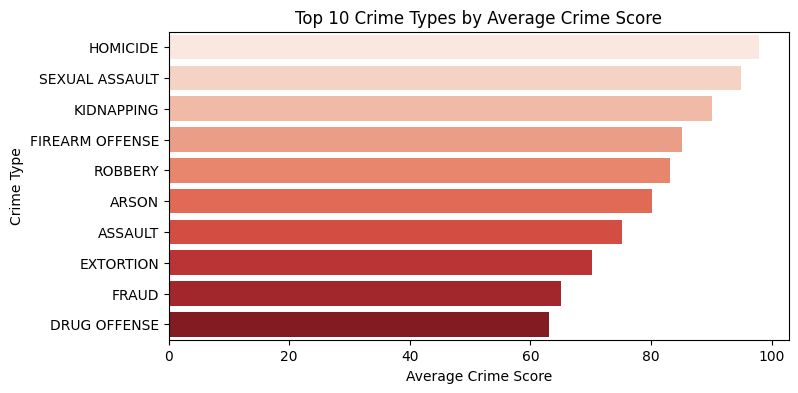

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Aggregate the average Crime Score by Crime Description
crime_severity = df.groupby("Crime Description")["Crime Score"].mean().sort_values(ascending=False).head(10)

# Plot the results
plt.figure(figsize=(8,4))
sns.barplot(x=crime_severity.values, y=crime_severity.index, palette="Reds")
plt.xlabel("Average Crime Score")
plt.ylabel("Crime Type")
plt.title("Top 10 Crime Types by Average Crime Score")
plt.show()


*Average Crime Score by Crime Domain*

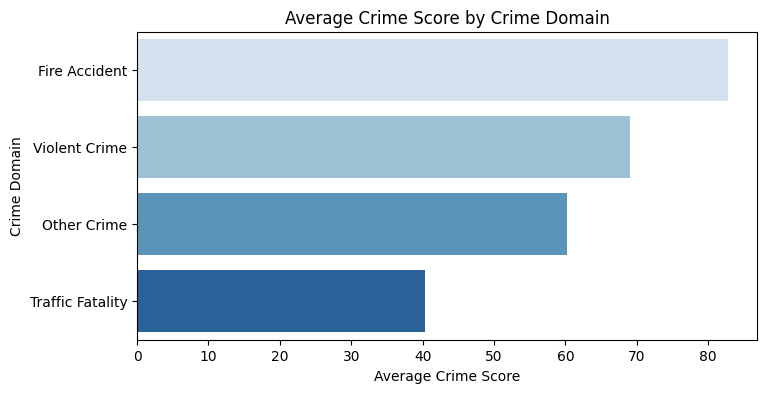

In [13]:
# Aggregate the average Crime Score by Crime Domain
crime_domain_severity = df.groupby("Crime Domain")["Crime Score"].mean().sort_values(ascending=False)

# Plot the results
plt.figure(figsize=(8,4))
sns.barplot(x=crime_domain_severity.values, y=crime_domain_severity.index, palette="Blues")
plt.xlabel("Average Crime Score")
plt.ylabel("Crime Domain")
plt.title("Average Crime Score by Crime Domain")
plt.show()


*Distribution of Crime Victims by Age and Gender*

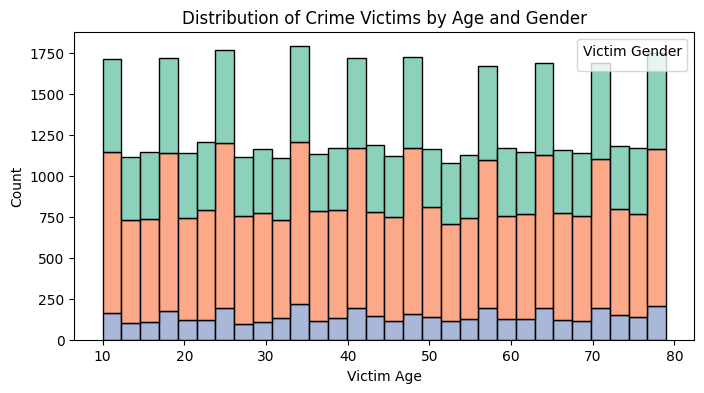

In [14]:
# Plot the distribution of crime victims by Victim Age and Victim Gender
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="Victim Age", hue="Victim Gender", multiple="stack", bins=30, palette="Set2")

# Labels and title
plt.xlabel("Victim Age")
plt.ylabel("Count")
plt.title("Distribution of Crime Victims by Age and Gender")
plt.legend(title="Victim Gender")
plt.show()


*Top 6 Most Frequently Used Weapons in Crimes*

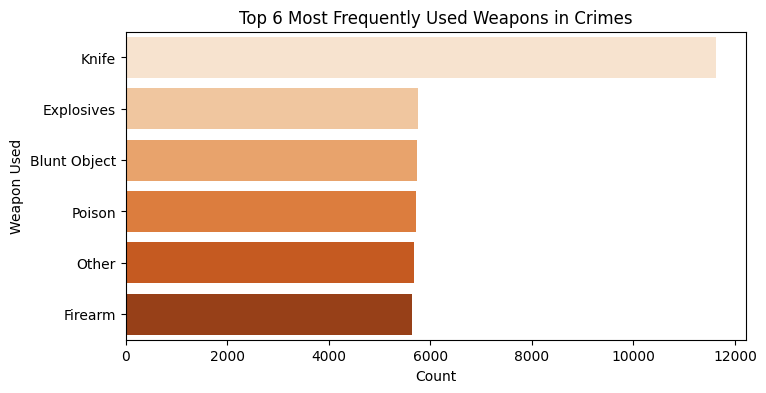

In [15]:
# Count the occurrences of each weapon type and display the top 10 most used weapons
weapon_counts = df["Weapon Used"].value_counts().head(10)

# Plot the results
plt.figure(figsize=(8,4))
sns.barplot(x=weapon_counts.values, y=weapon_counts.index, palette="Oranges")
plt.xlabel("Count")
plt.ylabel("Weapon Used")
plt.title("Top 6 Most Frequently Used Weapons in Crimes")
plt.show()


*Top 6 Weapon Types by Average Crime Score*

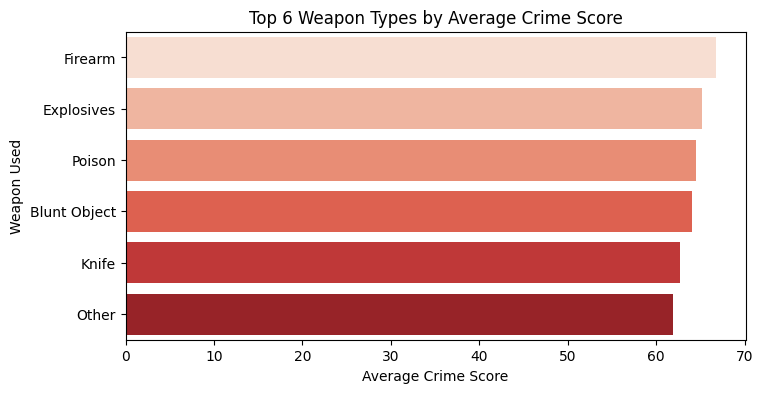

In [16]:
# Aggregate the average Crime Score by Weapon Used
weapon_severity = df.groupby("Weapon Used")["Crime Score"].mean().sort_values(ascending=False).head(10)

# Plot the results
plt.figure(figsize=(8,4))
sns.barplot(x=weapon_severity.values, y=weapon_severity.index, palette="Reds")
plt.xlabel("Average Crime Score")
plt.ylabel("Weapon Used")
plt.title("Top 6 Weapon Types by Average Crime Score")
plt.show()


*Top 10 Crime Hotspots by Locality and Population*

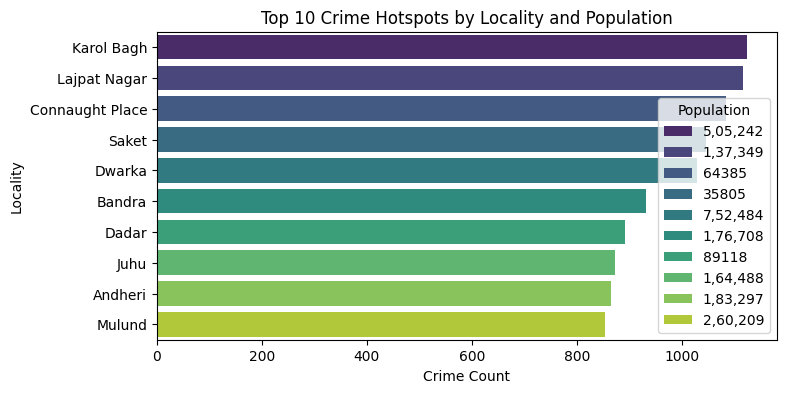

In [17]:
# Aggregate crime count by Locality and Population
crime_hotspots = df.groupby(["Locality", "Population"]).size().reset_index(name="Crime Count")

# Sort by highest crime count
crime_hotspots = crime_hotspots.sort_values(by="Crime Count", ascending=False).head(10)

# Plot the results
plt.figure(figsize=(8,4))
sns.barplot(x=crime_hotspots["Crime Count"], y=crime_hotspots["Locality"], hue=crime_hotspots["Population"], palette="viridis")
plt.xlabel("Crime Count")
plt.ylabel("Locality")
plt.title("Top 10 Crime Hotspots by Locality and Population")
plt.legend(title="Population")
plt.show()


*Gender-Based Crime Trends*

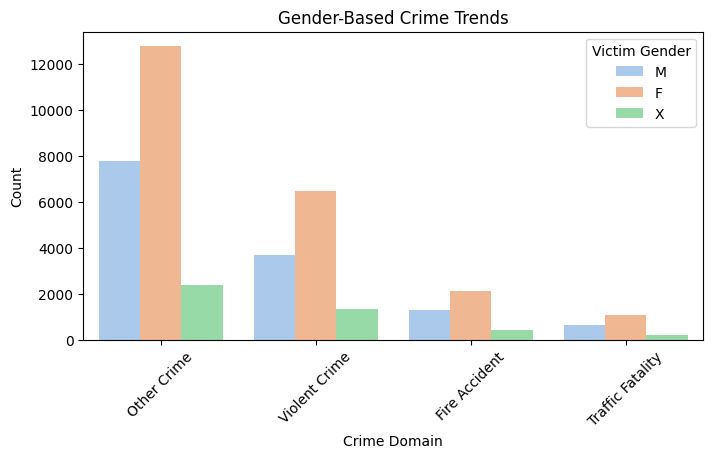

In [19]:
# Plot gender-based crime trends
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="Crime Domain", hue="Victim Gender", palette="pastel", order=df["Crime Domain"].value_counts().index[:10])

# Labels and title
plt.xlabel("Crime Domain")
plt.ylabel("Count")
plt.title("Gender-Based Crime Trends")
plt.xticks(rotation=45)
plt.legend(title="Victim Gender")

# Show plot
plt.show()


*Correlation between Victim Age and Crime Domain*

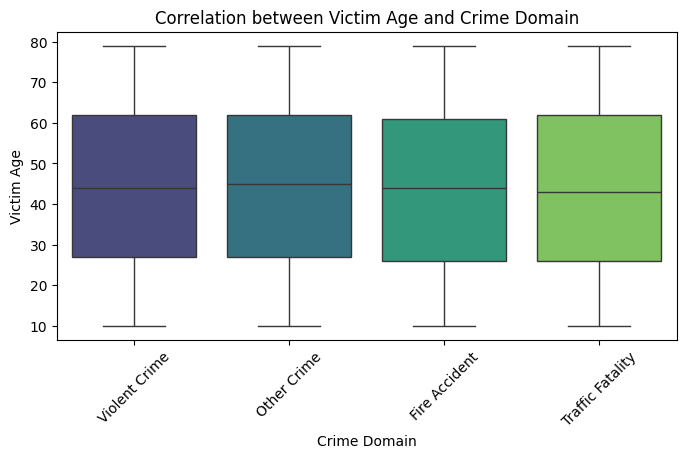

In [20]:
# Plot correlation between Victim Age and Crime Type (Top 10 crime types)
top_crimes = df["Crime Domain"].value_counts().nlargest(10).index
df_filtered = df[df["Crime Domain"].isin(top_crimes)]

plt.figure(figsize=(8,4))
sns.boxplot(data=df_filtered, x="Crime Domain", y="Victim Age", palette="viridis")

# Labels and title
plt.xlabel("Crime Domain")
plt.ylabel("Victim Age")
plt.title("Correlation between Victim Age and Crime Domain")
plt.xticks(rotation=45)

# Show plot
plt.show()


*Relationship between Crime Description and Weapon Used*

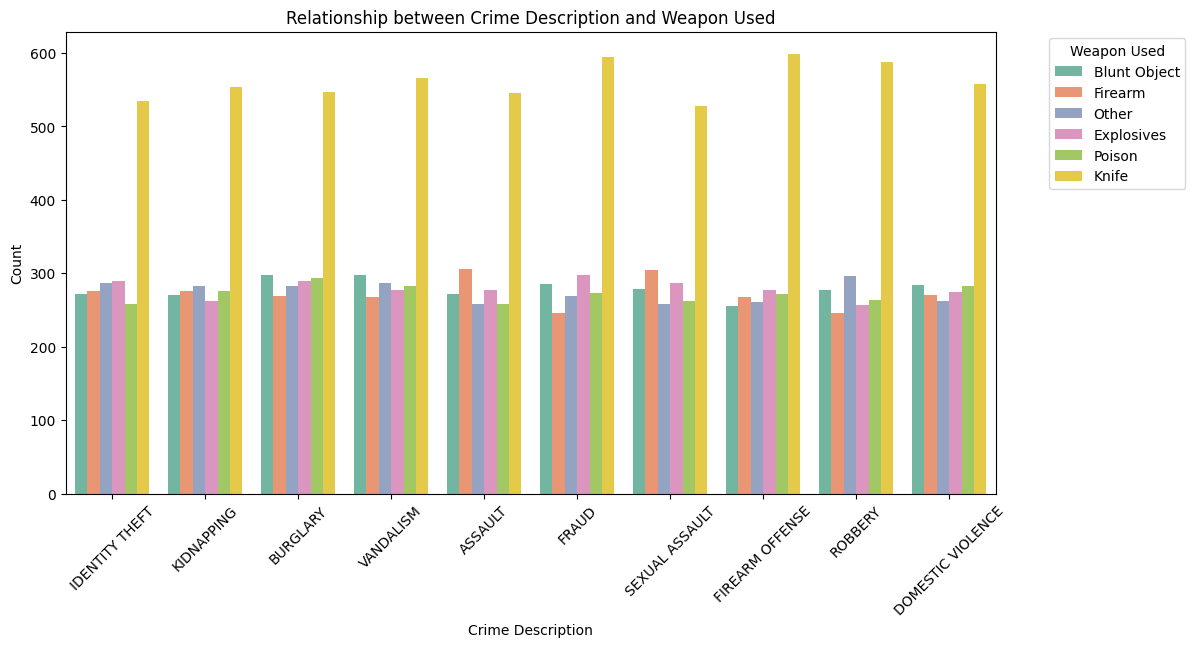

In [21]:
# Plot relationship between Crime Description and Weapon Used (Top 10 crimes)
top_crimes = df["Crime Description"].value_counts().nlargest(10).index
df_filtered = df[df["Crime Description"].isin(top_crimes)]

plt.figure(figsize=(12, 6))
sns.countplot(data=df_filtered, x="Crime Description", hue="Weapon Used", palette="Set2")

# Labels and title
plt.xlabel("Crime Description")
plt.ylabel("Count")
plt.title("Relationship between Crime Description and Weapon Used")
plt.xticks(rotation=45)
plt.legend(title="Weapon Used", bbox_to_anchor=(1.05, 1), loc="upper left")

# Show plot
plt.show()


In [22]:
import pandas as pd
import folium
from folium.plugins import HeatMap

file_path = 'lcrimedf.xlsx'  # Replace with your actual file path
df = pd.read_excel(file_path)

# Sample city-to-coordinates mapping (Replace with actual latitude/longitude if available)
city_coords = {
    "Delhi": [28.6139, 77.2090],
    "Mumbai": [19.0760, 72.8777],
    "Bangalore": [12.9716, 77.5946],
    "Kolkata": [22.5726, 88.3639],
    "Chennai": [13.0827, 80.2707],
}

# Filter dataset to keep only cities in our mapping
df_filtered = df[df["City"].isin(city_coords.keys())]

# Group by city and get crime count
crime_counts = df_filtered["City"].value_counts()

# Convert crime counts to standard Python int
heat_data = [[city_coords[city][0], city_coords[city][1], int(crime_counts[city])] for city in crime_counts.index]

# Create a folium map centered in India
m = folium.Map(location=[20.5937, 78.9629], zoom_start=5)

# Add heatmap layer
HeatMap(heat_data).add_to(m)

# Save the map and display
m.save("crime_hotspots_map1.html")
m


In [ ]:
# file_path = 'lcrimedf.xlsx'  # Replace with your actual file path
# df = pd.read_excel(file_path)

*Dropping Unneccesary Columns*

In [27]:
# Drop the specified columns
columns_to_drop = ['Date Reported','Date of Occurrence','Time of Occurrence','Population','Crime Code','Date Case Closed','Case Closed','Police Deployed','Report Number']  # Replace with the exact column names or indices
df = df.drop(columns=columns_to_drop, errors='ignore')

*Value Counts*

In [29]:
df['City'].value_counts()

City
Delhi            5400
Mumbai           4415
Bangalore        3588
Hyderabad        2881
Kolkata          2518
Chennai          2493
Pune             2212
Ahmedabad        1817
Jaipur           1479
Lucknow          1456
Kanpur           1112
Surat            1111
Nagpur           1053
Agra              764
Ludhiana          761
Visakhapatnam     728
Thane             706
Ghaziabad         704
Indore            699
Patna             695
Bhopal            690
Meerut            395
Srinagar          371
Nashik            366
Vasai             362
Varanasi          355
Kalyan            355
Faridabad         354
Rajkot            320
Name: count, dtype: int64

In [30]:
df['Crime Description'].value_counts()

Crime Description
BURGLARY               1980
VANDALISM              1975
FRAUD                  1965
DOMESTIC VIOLENCE      1932
FIREARM OFFENSE        1931
ROBBERY                1928
KIDNAPPING             1920
IDENTITY THEFT         1918
SEXUAL ASSAULT         1917
ASSAULT                1915
TRAFFIC VIOLATION      1915
PUBLIC INTOXICATION    1912
HOMICIDE               1909
CYBERCRIME             1899
ILLEGAL POSSESSION     1895
ARSON                  1894
DRUG OFFENSE           1890
EXTORTION              1873
COUNTERFEITING         1871
VEHICLE - STOLEN       1862
SHOPLIFTING            1859
Name: count, dtype: int64

In [31]:
df['Victim Gender'].value_counts()

Victim Gender
F    22423
M    13405
X     4332
Name: count, dtype: int64

In [32]:
df['Weapon Used'].value_counts()

Weapon Used
Knife           5835
Explosives      5751
Blunt Object    5737
Poison          5728
Other           5676
Firearm         5643
Name: count, dtype: int64

In [33]:
df['Locality'].value_counts()

Locality
Karol Bagh         1125
Lajpat Nagar       1116
Connaught Place    1084
Saket              1046
Dwarka             1029
                   ... 
Indira Circle        61
Phulwaria            59
Nashik Road          59
Pisawali             56
Raiya Road           53
Name: count, Length: 142, dtype: int64

In [34]:
df['Crime Domain'].value_counts()

Crime Domain
Other Crime         22948
Violent Crime       11472
Fire Accident        3825
Traffic Fatality     1915
Name: count, dtype: int64

*Label Encoding*

In [35]:
from sklearn.preprocessing import LabelEncoder

# List of categorical columns to encode
categorical_columns = ['City','Crime Description','Victim Gender','Weapon Used','Locality','Crime Domain']

# Initialize the label encoder
label_encoder = LabelEncoder()

# Apply label encoding to each of the categorical columns
for col in categorical_columns:
    df[col] = label_encoder.fit_transform(df[col])

# Display the first few rows of the updated dataset
df['City'].value_counts()


City
5     5400
17    4415
2     3588
8     2881
13    2518
4     2493
21    2212
1     1817
10    1479
14    1456
12    1112
24    1111
18    1053
0      764
15     761
28     728
25     706
7      704
9      699
20     695
3      690
16     395
23     371
19     366
27     362
26     355
11     355
6      354
22     320
Name: count, dtype: int64

In [36]:
df['Crime Domain'].value_counts()

Crime Domain
1    22948
3    11472
0     3825
2     1915
Name: count, dtype: int64

In [37]:
df['Crime Description'].value_counts()

Crime Description
2     1980
19    1975
9     1965
5     1932
8     1931
15    1928
13    1920
11    1918
16    1917
1     1915
18    1915
14    1912
10    1909
4     1899
12    1895
0     1894
6     1890
7     1873
3     1871
20    1862
17    1859
Name: count, dtype: int64

In [38]:
df['Victim Gender'].value_counts()

Victim Gender
0    22423
1    13405
2     4332
Name: count, dtype: int64

In [39]:
df['Weapon Used'].value_counts()

Weapon Used
3    5835
6    5790
1    5751
0    5737
5    5728
4    5676
2    5643
Name: count, dtype: int64

In [40]:
df['Locality'].value_counts()

Locality
61     1125
72     1116
27     1084
111    1046
32     1029
       ... 
49       61
101      59
90       59
104      56
105      53
Name: count, Length: 142, dtype: int64

*Data Correlation*

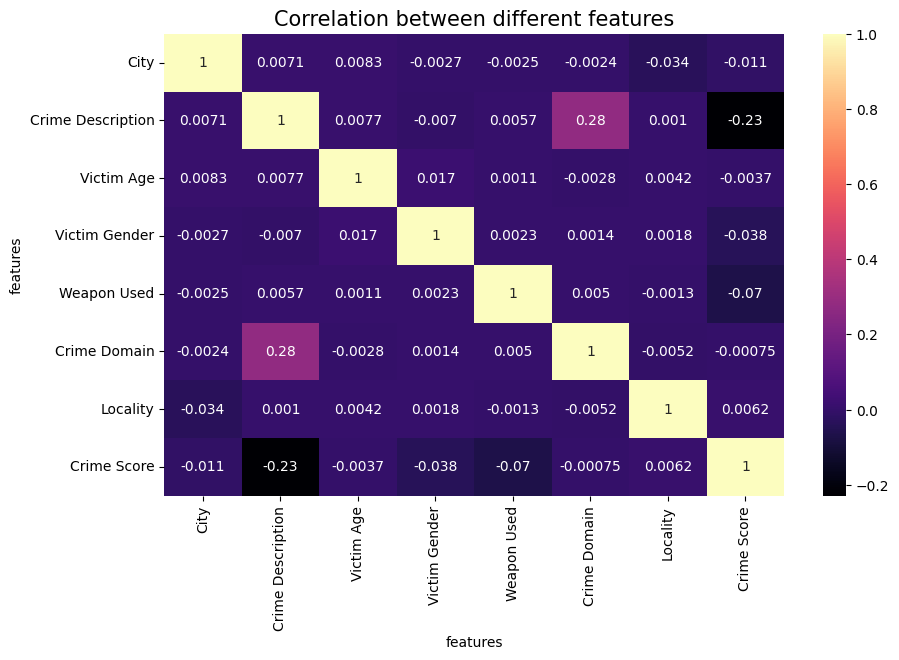

In [41]:

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.heatmap(df.corr(), annot=True,cmap='magma')
ax.set(xlabel='features')
ax.set(ylabel='features')

plt.title('Correlation between different features', fontsize = 15, c='black')
plt.show()

*Saving Cleaned File*

In [42]:
df.to_csv('cleaned_data.csv',index=False)

crime = pd.read_csv('cleaned_data.csv')
crime

,City,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Locality,Crime Score
0,1,11,16,1,0,3,137,61
1,4,10,37,1,5,1,124,99
2,15,13,48,0,0,1,96,89
3,21,2,49,0,2,1,15,56
4,21,19,30,0,4,1,45,39
...,...,...,...,...,...,...,...,...
40155,13,3,78,0,2,1,31,62
40156,17,12,75,0,6,1,6,31
40157,12,20,68,1,4,3,8,48
40158,20,16,11,1,0,3,81,99


**MACHINE LEARNING MODELS**

*Splitting Of Data*

In [46]:
from sklearn.model_selection import train_test_split

# Assume df is your DataFrame
# Define feature set and target label
X = df.drop(columns=['Crime Score'])
y = df['Crime Score']


# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Optionally, print the shapes of the resulting splits
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (32128, 7)
y_train shape:  (32128,)
X_test shape:  (8032, 7)
y_test shape:  (8032,)


*Adaptive Region Partitioning (ARP)*

In [47]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators = 150 ,max_depth = 30, min_samples_leaf = 5, min_samples_split = 30)
rf.fit(X_train,y_train)

RandomForestRegressor(max_depth=30, min_samples_leaf=5, min_samples_split=30,
                      n_estimators=150)

In [48]:
y_pred = rf.predict(X_test) 

*Accuracy*

In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Print the evaluation metrics
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)


Mean Absolute Error (MAE): 1.9758666565543033
Mean Squared Error (MSE): 6.124603423921226
Root Mean Squared Error (RMSE): 2.474793612388966
R² Score: 0.9833589411315589


*Other Models*

In [58]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Initialize models
dt = DecisionTreeRegressor(max_depth=30, min_samples_leaf=5, min_samples_split=30)
lr = LogisticRegression(max_iter=1000)  # Logistic Regression is mainly for classification, but using it for reference
lgbm = LGBMRegressor(n_estimators=150, max_depth=30, min_child_samples=5)
xgb = XGBRegressor(n_estimators=150, max_depth=30, min_child_weight=5)
ada = AdaBoostRegressor(n_estimators=150)

# Fit models
dt.fit(X_train, y_train)
lr.fit(X_train, y_train)
lgbm.fit(X_train, y_train)
xgb.fit(X_train, y_train)
ada.fit(X_train, y_train)

# Predictions
dt_pred = dt.predict(X_test)
lr_pred = lr.predict(X_test)
lgbm_pred = lgbm.predict(X_test)
xgb_pred = xgb.predict(X_test)
ada_pred = ada.predict(X_test)

# Function to evaluate models
def evaluate_model(y_test, y_pred, model_name):
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"{model_name} Performance:")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"R² Score: {r2:.4f}")
    print("-" * 40)

# Evaluate all models
evaluate_model(y_test, dt_pred, "Decision Tree")
evaluate_model(y_test, lr_pred, "Logistic Regression")
evaluate_model(y_test, lgbm_pred, "LightGBM")
evaluate_model(y_test, xgb_pred, "XGBoost")
evaluate_model(y_test, ada_pred, "AdaBoost")


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008520 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 277
[LightGBM] [Info] Number of data points in the train set: 32128, number of used features: 7
[LightGBM] [Info] Start training from score 63.993152
Decision Tree Performance:
Mean Squared Error (MSE): 6.9376
Mean Absolute Error (MAE): 2.0990
R² Score: 0.9811
----------------------------------------
Logistic Regression Performance:
Mean Squared Error (MSE): 608.9678
Mean Absolute Error (MAE): 16.3741
R² Score: -0.6546
----------------------------------------
LightGBM Performance:
Mean Squared Error (MSE): 5.7617
Mean Absolute Error (MAE): 1.9205
R² Score: 0.9843
----------------------------------------
XGBoost Performance:
Mean Squared Error (MSE): 8.0674


*Saving Model*

In [50]:
import pickle 

In [51]:
# save the model
model = rf  # Your machine learning model object
file_path = 'rf-cyber.pkl'  # Path to the file where you want to save the model

with open(file_path, 'wb') as file:
    pickle.dump(model, file)

In [52]:
import pickle
# load the model

file_path = 'rf-cyber.pkl'  # Path to the saved model file

with open(file_path, 'rb') as file:
    loaded_model = pickle.load(file)

In [53]:
X_train.columns

Index(['City', 'Crime Description', 'Victim Age', 'Victim Gender',
       'Weapon Used', 'Crime Domain', 'Locality'],
      dtype='object')

*User's Prediction*

In [54]:
loaded_model.predict([[1,11,16,1,0,3,137]])

array([58.36402995])

In [55]:
loaded_model.predict([[21,19,30,0,4,1,45]])

array([42.22953669])

In [56]:
loaded_model.predict([[4,14,29,1,3,1,88]])

array([54.23418322])